<a href="https://colab.research.google.com/github/Gitanjali2495/Html/blob/main/Smart_campus_Energy_Analyzer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Smart Campus Energy Analyzer & Predictor
### Using Simple Linear Regression

**Project Overview:**

This project analyzes the relationship between computer lab operating hours and electricity consumption using Simple Linear Regression.

The model learns from sample data and predicts electricity consumption based on the number of operating hours.

**Objectives:**
- Analyze electricity consumption data.
- Visualize relationships using graphs.
- Build a Linear Regression model.
- Evaluate model performance.
- Predict electricity consumption for new inputs.

**Technology Used:** Python, Pandas, NumPy, Matplotlib, Scikit-learn, Google Colab.

## 1. Importing Libraries

In this step, we import the required Python libraries for data analysis, visualization, model training and performance evaluation.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("All libraries imported successfully!")

All libraries imported successfully!


## 2. Dataset Creation

In this step, we create a sample dataset containing computer lab operating hours and electricity consumption.

The dataset is used to train and test the Linear Regression model.

Note: The dataset contains illustrative synthetic values, not actual college meter readings.

In [ ]:
data = {
    "Operating_Hours": [
        2, 3, 4, 5, 6, 7, 8, 9,
        10, 3, 5, 7, 8, 9, 10,
        4, 6, 8, 2, 9, 5, 7, 10, 6
    ],

    "Electricity_Consumption": [
        12, 15, 18, 21, 24, 28, 31, 34,
        38, 14, 22, 27, 33, 32, 41,
        19, 26, 30, 11, 36, 23, 29, 40, 25
    ]
}

df = pd.DataFrame(data)

print(df)

    Operating_Hours  Electricity_Consumption
0                 2                       12
1                 3                       15
2                 4                       18
3                 5                       21
4                 6                       24
5                 7                       28
6                 8                       31
7                 9                       34
8                10                       38
9                 3                       14
10                5                       22
11                7                       27
12                8                       33
13                9                       32
14               10                       41
15                4                       19
16                6                       26
17                8                       30
18                2                       11
19                9                       36
20                5                       23
21        

## 3. Data Exploration and Analysis

Data exploration helps us understand the structure and quality of the dataset.

We check the number of records, data types, statistical summary, missing values and duplicate records.

In [ ]:
print("Dataset Shape:")
print(df.shape)

print("\nDataset Information:")
print(df.info())

print("\nStatistical Summary:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

Dataset Shape:
(24, 2)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24 entries, 0 to 23
Data columns (total 2 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   Operating_Hours          24 non-null     int64
 1   Electricity_Consumption  24 non-null     int64
dtypes: int64(2)
memory usage: 516.0 bytes
None

Statistical Summary:
       Operating_Hours  Electricity_Consumption
count        24.000000                24.000000
mean          6.375000                26.208333
std           2.533472                 8.652615
min           2.000000                11.000000
25%           4.750000                20.500000
50%           6.500000                26.500000
75%           8.250000                32.250000
max          10.000000                41.000000

Missing Values:
Operating_Hours            0
Electricity_Consumption    0
dtype: int64

Duplicate Records:
0


## 4. Data Visualization

Data visualization helps us understand the relationship between operating hours and electricity consumption.

A scatter plot is used to identify the direction and approximate linear pattern of the relationship.

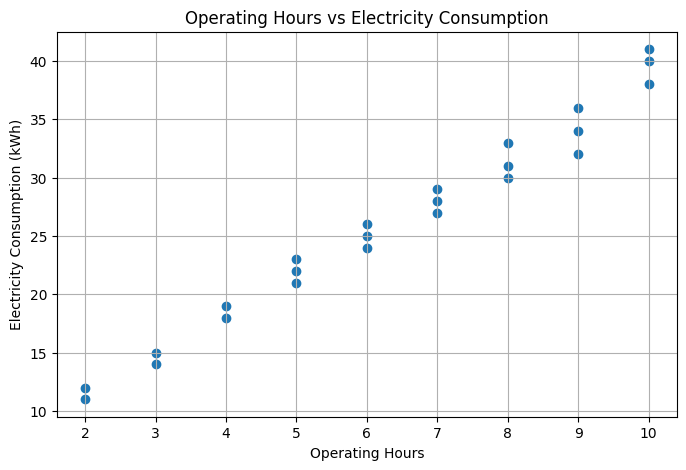

In [ ]:
plt.figure(figsize=(8,5))

plt.scatter(
    df["Operating_Hours"],
    df["Electricity_Consumption"]
)

plt.xlabel("Operating Hours")
plt.ylabel("Electricity Consumption (kWh)")

plt.title("Operating Hours vs Electricity Consumption")

plt.grid(True)
plt.show()

## 5. Feature Selection

In this step, we select the independent and dependent variables.

- X represents the independent variable (Operating Hours).
- y represents the dependent variable (Electricity Consumption).

The model uses X to predict y.

In [ ]:
X = df[["Operating_Hours"]]

y = df["Electricity_Consumption"]

print("Input Variable:")
print(X.head())

print("\nTarget Variable:")
print(y.head())

Input Variable:
   Operating_Hours
0                2
1                3
2                4
3                5
4                6

Target Variable:
0    12
1    15
2    18
3    21
4    24
Name: Electricity_Consumption, dtype: int64


## 6. Train-Test Split

The dataset is divided into training and testing sets.

80% of the data is used to train the model, while 20% is used to evaluate its performance on unseen data.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Data:", X_train.shape)

print("Testing Data:", X_test.shape)

Training Data: (19, 1)
Testing Data: (5, 1)


## 7. Linear Regression Model Training

In this step, we create and train a Simple Linear Regression model using the training dataset.

The model learns the best-fit regression line by minimizing the squared prediction errors.

The regression equation is:

ŷ = mx + b

In [ ]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")

print("Slope:", model.coef_[0])

print("Intercept:", model.intercept_)

Linear Regression Model Trained Successfully!
Slope: 3.4180602006688967
Intercept: 4.438127090300998


## 8. Model Prediction

After training, the model predicts electricity consumption using the testing dataset.

We compare actual values with predicted values to understand the model's performance.

In [ ]:
y_pred = model.predict(X_test)

comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

print(comparison)

   Actual  Predicted
0      38  38.618729
1      26  24.946488
2      12  11.274247
3      11  11.274247
4      27  28.364548


## 9. Model Performance Evaluation

We evaluate the Linear Regression model using four performance metrics:

- MAE: Measures average absolute prediction error.
- MSE: Measures average squared prediction error.
- RMSE: Measures prediction error in the original target units.
- R² Score: Measures model fit compared with a mean-value baseline.

In [ ]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("Model Performance")

print("MAE:", mae)

print("MSE:", mse)

print("RMSE:", rmse)

print("R2 Score:", r2)

Model Performance
MAE: 0.8073578595317727
MSE: 0.7913267189405045
RMSE: 0.8895654663601238
R2 Score: 0.9923142315565219


## 10. Regression Line Visualization

In this step, we visualize the actual observations and the fitted regression line.

The graph helps us understand how well the model represents the relationship between the two variables.

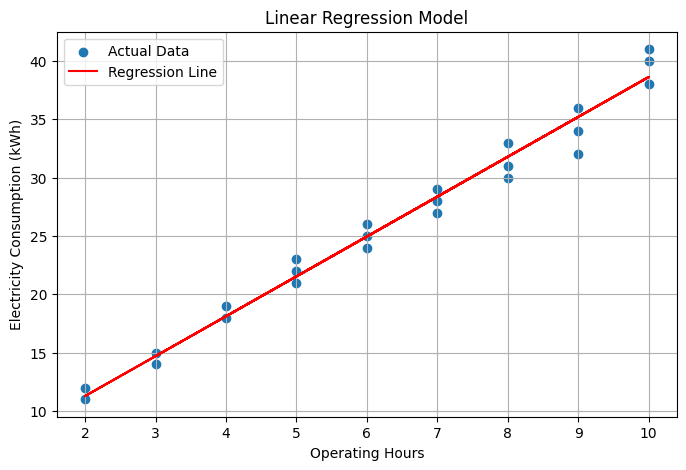

In [ ]:
plt.figure(figsize=(8,5))

plt.scatter(
    X,
    y,
    label="Actual Data"
)

plt.plot(
    X,
    model.predict(X),
    color="red",
    label="Regression Line"
)

plt.xlabel("Operating Hours")

plt.ylabel("Electricity Consumption (kWh)")

plt.title("Linear Regression Model")

plt.legend()

plt.grid(True)

plt.show()

## 11. Residual Analysis

Residuals represent the difference between actual and predicted values.

Residual analysis helps us inspect prediction errors and identify unusual patterns in the model.

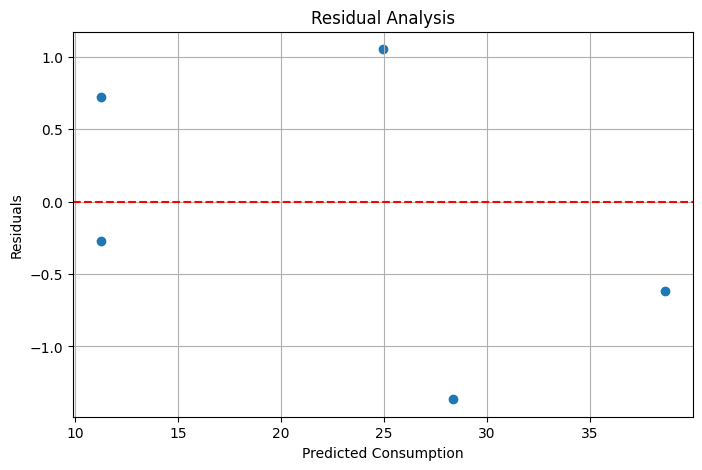

In [ ]:
residuals = y_test.values - y_pred

plt.figure(figsize=(8,5))

plt.scatter(y_pred, residuals)

plt.axhline(
    y=0,
    color="red",
    linestyle="--"
)

plt.xlabel("Predicted Consumption")

plt.ylabel("Residuals")

plt.title("Residual Analysis")

plt.grid(True)

plt.show()

## 12. Interactive Electricity Consumption Prediction

This is the final stage of the project.

The user can enter the computer lab operating hours, and the trained Linear Regression model predicts the expected electricity consumption in kWh.

In [ ]:
hours = float(input("Enter lab operating hours: "))

if hours < 2 or hours > 10:
    print("Warning: Prediction is outside the dataset range.")

prediction = model.predict(
    pd.DataFrame({
        "Operating_Hours": [hours]
    })
)

print("Operating Hours:", hours)

print(
    "Predicted Electricity Consumption:",
    round(prediction[0], 2),
    "kWh"
)

Enter lab operating hours: 5
Operating Hours: 5.0
Predicted Electricity Consumption: 21.53 kWh


## 13. Conclusion

The Smart Campus Energy Analyzer & Predictor successfully demonstrates the application of Simple Linear Regression.

The project analyzes the relationship between computer lab operating hours and electricity consumption. It trains a prediction model, evaluates its performance using different metrics, visualizes the regression line and predicts electricity consumption for new input values.

This project provides practical understanding of data analysis, visualization and supervised machine learning.